[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JMasr/ai-tutorials/blob/main/en/whisper-rlora.ipynb)

Author: José Manuel Ramírez Sánchez · https://jmramirez.engineer

# Radial LoRA (R-LoRA) on Whisper, implemented from scratch

This notebook implements **R-LoRA (Radial Low-Rank Adaptation)** in plain PyTorch and
applies it to a **Whisper** model, following the same steps as the
[PEFT + LoRA on Whisper](https://github.com/JMasr/ai-tutorials/blob/main/en/whisper-peft-lora.ipynb)
tutorial: a classifier via a *downstream task* (Part A) and an embedding extractor
(Part B), on the same synthetic data, so the two notebooks can be read side by side.

R-LoRA is a one-parameter change to LoRA: before the low-rank projection, the
adapter's input is divided by its norm raised to a learnable exponent λ ∈ [0, 1].
It was introduced for low-resource clinical speech (IberSPEECH 2026), where it
beats LoRA by 12.4 Macro-F1 points on four corpora, and it was used to adapt
Whisper-large-v3 in the ALBAYZIN 2026 speech recognition challenge. The `peft`
library does not include it, so here it is written as a small `nn.Module` that
wraps any `nn.Linear` -- which also means it works on any Transformer, not only
Whisper.

**What you will do:**
1. Write `RLoRALinear` and check its three defining properties numerically.
2. Inject it into Whisper's encoder and train a classifier, next to a LoRA
   baseline with the same rank.
3. Read the exponents λ the model learned, save and reload the adapter, and see
   why it cannot be merged into the weights.
4. Repeat the embedding-extractor recipe of the LoRA tutorial with R-LoRA.

**Notebook design:** CPU only, synthetic tones, `openai/whisper-tiny`.

> Estimated total runtime: **~4 minutes** on an 8-core CPU without a GPU (including the model download).

**Requirements:** install the dependencies before you start (on Colab, run it in a cell as `%pip install ...`):

```bash
pip install torch transformers==4.57.6 peft==0.20.0 scikit-learn matplotlib
```

## 0. R-LoRA on one page

LoRA freezes a pretrained weight $W_0 \in \mathbb{R}^{d\times k}$ and adds a low-rank update:

$$ h = W_0 x + \tfrac{\alpha}{r}\, B A x, \qquad B \in \mathbb{R}^{d\times r},\ A \in \mathbb{R}^{r\times k},\ r \ll \min(d,k) $$

That update is **linear in $x$**: it responds to how large an activation is just as
much as to the direction it points. Inside a Transformer, layer normalisation keeps
hidden states on a sphere and, in high dimensions, angles are more informative than
distances. R-LoRA conditions the update on the direction by tempering the input norm:

$$ T_\lambda(x) = \frac{x}{(\lVert x\rVert_2 + \varepsilon)^{\lambda}}, \qquad \lambda = \sigma(\lambda_{\text{raw}}) \in [0, 1], \qquad h = W_0 x + \tfrac{\alpha}{r}\, B A\, T_\lambda(x) $$

| λ | What the branch sees |
|---|---|
| 0 | the raw input: plain LoRA |
| 1 | the input projected onto the unit sphere: direction only |
| in between | the direction plus part of the magnitude |

- **One learnable scalar per adapted layer** ($\lambda_{\text{raw}}$), on top of LoRA's $r(d+k)$.
- **Same initialisation as LoRA**: $A$ Kaiming-uniform, $B = 0$, so training starts exactly
  from the pretrained model. $\lambda_{\text{raw}} = 0.5$, i.e. $\lambda_0 \approx 0.62$.
- **The price**: $T_\lambda$ is non-linear, so the update cannot be folded into $W_0$ after
  training; the branch runs at every forward pass (under 1 % extra time in the paper).

In [1]:
import os

# Force CPU explicitly, as in the LoRA tutorial.
os.environ["CUDA_VISIBLE_DEVICES"] = ""

import math
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import torch
import torch.nn as nn

torch.manual_seed(0)
np.random.seed(0)
DEVICE = torch.device("cpu")

import peft
import transformers

transformers.logging.set_verbosity_error()
print("torch       :", torch.__version__)
print("transformers:", transformers.__version__)
print("peft        :", peft.__version__, "(only for the LoRA baseline)")

torch       : 2.14.0+cpu
transformers: 4.57.6
peft        : 0.20.0 (only for the LoRA baseline)


## 1. Synthetic data and features

The same data as the LoRA tutorial: 1-second sine tones at 16 kHz, two classes defined by
their base frequency, plus Gaussian noise. They are turned into Whisper's log-mel input,
always padded to 30 seconds (3000 frames).

In [2]:
from transformers import WhisperFeatureExtractor

SAMPLE_RATE = 16_000
DURATION_S = 1.0
CLASS_FREQS = (220.0, 660.0)
NOISE_STD = 0.05
CHECKPOINT = "openai/whisper-tiny"


def make_example(label: int, rng: np.random.Generator) -> np.ndarray:
    t = np.linspace(0, DURATION_S, int(SAMPLE_RATE * DURATION_S), endpoint=False)
    freq = CLASS_FREQS[label] * (1 + 0.05 * rng.standard_normal())
    wave = 0.3 * np.sin(2 * np.pi * freq * t) + NOISE_STD * rng.standard_normal(t.shape)
    return wave.astype(np.float32)


def make_dataset(n_per_class: int, seed: int) -> tuple[list[np.ndarray], list[int]]:
    rng = np.random.default_rng(seed)
    waves, labels = [], []
    for label in (0, 1):
        for _ in range(n_per_class):
            waves.append(make_example(label, rng))
            labels.append(label)
    return waves, labels


feature_extractor = WhisperFeatureExtractor.from_pretrained(CHECKPOINT)


def to_batch(waves, labels):
    feats = feature_extractor(waves, sampling_rate=SAMPLE_RATE, return_tensors="pt")
    return feats["input_features"], torch.tensor(labels)


X_train, y_train = to_batch(*make_dataset(n_per_class=10, seed=2))
X_val, y_val = to_batch(*make_dataset(n_per_class=4, seed=3))
print("train:", tuple(X_train.shape), "| val:", tuple(X_val.shape))

train: (20, 80, 3000) | val: (8, 80, 3000)


## 2. Implementing R-LoRA

`RLoRALinear` wraps an existing `nn.Linear`. The wrapped layer stays frozen; the module adds
`lora_A`, `lora_B` and one scalar `lambda_raw`. The forward pass is the equation above, line by line.

In [3]:
class RLoRALinear(nn.Module):
    """A frozen nn.Linear plus a radial low-rank branch: h = W0 x + (alpha/r) B A T_lambda(x)."""

    def __init__(self, base: nn.Linear, r: int = 8, alpha: float = 16.0,
                 dropout: float = 0.0, lambda_raw_init: float = 0.5, eps: float = 1e-6):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False
        self.lora_A = nn.Linear(base.in_features, r, bias=False)
        self.lora_B = nn.Linear(r, base.out_features, bias=False)
        nn.init.kaiming_uniform_(self.lora_A.weight, a=math.sqrt(5))  # as in LoRA
        nn.init.zeros_(self.lora_B.weight)                              # branch starts at zero
        self.lambda_raw = nn.Parameter(torch.tensor(float(lambda_raw_init)))
        self.scaling = alpha / r
        self.dropout = nn.Dropout(dropout)
        self.eps = eps

    @property
    def lam(self) -> torch.Tensor:
        return torch.sigmoid(self.lambda_raw)  # keeps lambda in [0, 1]

    def radial(self, x: torch.Tensor) -> torch.Tensor:
        # T_lambda(x) = x / (||x|| + eps) ** lambda, norm taken over the feature axis
        return x / (x.norm(dim=-1, keepdim=True) + self.eps) ** self.lam

    def branch(self, x: torch.Tensor) -> torch.Tensor:
        return self.lora_B(self.lora_A(self.dropout(self.radial(x)))) * self.scaling

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.base(x) + self.branch(x)

### 2.1 Three checks before using it

On a stand-alone layer with random inputs:

1. **At initialisation it is the frozen layer** (because $B = 0$).
2. **With λ → 0 it is exactly LoRA** (same $A$, $B$, scaling).
3. **It is not linear in $x$**: doubling the input does not double the branch's output
   unless λ = 0. This is what makes it unmergeable.

In [4]:
torch.manual_seed(0)
layer = RLoRALinear(nn.Linear(384, 384), r=8, alpha=16)
x = torch.randn(2, 5, 384) * 3.0

# 1. B = 0 -> identical to the frozen layer
print("1. max |R-LoRA(x) - W0 x| at init:", (layer(x) - layer.base(x)).abs().max().item())

# Give B some values so the branch is not zero for checks 2 and 3
nn.init.normal_(layer.lora_B.weight, std=0.02)

# 2. lambda -> 0 recovers LoRA
with torch.no_grad():
    layer.lambda_raw.fill_(-30.0)  # sigmoid(-30) ~ 1e-13
lora_out = layer.base(x) + layer.lora_B(layer.lora_A(x)) * layer.scaling
print("2. max |R-LoRA - LoRA| with lambda ~ 0:", (layer(x) - lora_out).abs().max().item())

# 3. non-linearity: branch(2x) vs 2 * branch(x), at the default lambda
with torch.no_grad():
    layer.lambda_raw.fill_(0.5)
    ratio = (layer.branch(2 * x).norm() / layer.branch(x).norm()).item()
print(f"3. ||branch(2x)|| / ||branch(x)|| = {ratio:.3f}  (LoRA would give 2.000; here 2^(1-lambda) = {2 ** (1 - layer.lam.item()):.3f})")

1. max |R-LoRA(x) - W0 x| at init: 0.0
2. max |R-LoRA - LoRA| with lambda ~ 0: 0.0
3. ||branch(2x)|| / ||branch(x)|| = 1.299  (LoRA would give 2.000; here 2^(1-lambda) = 1.299)


## 2.2 Injecting it into a model

`inject_rlora` walks the model and replaces every `nn.Linear` whose attribute name is in
`target_modules` -- the same idea as `LoraConfig(target_modules=...)` in `peft`. Everything
else is frozen, except the layers listed in `modules_to_save`, which are trained in full.
Nothing here is specific to Whisper: the same function works on a BERT, a ViT or a
Wav2Vec2, because it only looks for linear layers by name.

In [5]:
def inject_rlora(model: nn.Module, target_modules, r=8, alpha=16.0, dropout=0.0, modules_to_save=()):
    for p in model.parameters():
        p.requires_grad = False
    n_replaced = 0
    for parent in list(model.modules()):
        for name, child in list(parent.named_children()):
            if name in target_modules and isinstance(child, nn.Linear):
                setattr(parent, name, RLoRALinear(child, r=r, alpha=alpha, dropout=dropout))
                n_replaced += 1
    for name in modules_to_save:  # new, randomly initialised heads -> trained in full
        for p in getattr(model, name).parameters():
            p.requires_grad = True
    return n_replaced


def count_trainable(model: nn.Module) -> tuple[int, int]:
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

## 3. Part A -- Whisper as a classifier, R-LoRA next to LoRA

Same set-up as Part A of the LoRA tutorial: `WhisperForAudioClassification`, adapters on
`q_proj` and `v_proj` of the encoder's self-attention, rank 8, α = 16, and the new
`projector` and `classifier` trained in full. The LoRA baseline uses `peft` with exactly the
same settings and the same random seed, so the only difference is the radial operator.

In [6]:
from peft import LoraConfig, get_peft_model
from transformers import WhisperForAudioClassification

R, ALPHA, TARGETS, HEADS = 8, 16, ("q_proj", "v_proj"), ("projector", "classifier")

torch.manual_seed(0)
rlora_clf = WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2)
n_layers = inject_rlora(rlora_clf, TARGETS, r=R, alpha=ALPHA, modules_to_save=HEADS)

torch.manual_seed(0)
lora_clf = get_peft_model(
    WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2),
    LoraConfig(r=R, lora_alpha=ALPHA, lora_dropout=0.0, target_modules=list(TARGETS), modules_to_save=list(HEADS)),
)

for name, m in (("LoRA  ", lora_clf), ("R-LoRA", rlora_clf)):
    trainable, total = count_trainable(m)
    print(f"{name}: trainable {trainable:,} of {total:,} ({100 * trainable / total:.2f}%)")
print(f"R-LoRA adds {n_layers} parameters: one lambda per adapted layer")

LoRA  : trainable 148,226 of 8,455,684 (1.75%)
R-LoRA: trainable 148,234 of 8,356,618 (1.77%)
R-LoRA adds 8 parameters: one lambda per adapted layer


In [7]:
def accuracy(model, X, y) -> float:
    model.eval()
    with torch.no_grad():
        return (model(input_features=X).logits.argmax(dim=-1) == y).float().mean().item()


def train(model, n_epochs=3, batch_size=4, lr=1e-3, lr_adapters=None, seed=0, label=""):
    torch.manual_seed(seed)
    head = [p for n, p in model.named_parameters() if p.requires_grad and ("projector" in n or "classifier" in n)]
    adapters = [p for n, p in model.named_parameters() if p.requires_grad and not ("projector" in n or "classifier" in n)]
    opt = torch.optim.AdamW([{"params": head, "lr": lr}, {"params": adapters, "lr": lr_adapters or lr}])
    t0 = time.time()
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(X_train.shape[0])
        for i in range(0, X_train.shape[0], batch_size):
            idx = perm[i : i + batch_size]
            opt.zero_grad()
            out = model(input_features=X_train[idx], labels=y_train[idx])
            out.loss.backward()
            opt.step()
        print(f"{label} epoch {epoch} | loss {out.loss.item():.4f} | val acc {accuracy(model, X_val, y_val):.3f} | {time.time() - t0:.1f}s")
    return time.time() - t0


print(f"before training -- LoRA val acc {accuracy(lora_clf, X_val, y_val):.3f} | R-LoRA val acc {accuracy(rlora_clf, X_val, y_val):.3f}")
t_lora = train(lora_clf, label="LoRA  ")
t_rlora = train(rlora_clf, label="R-LoRA")  # same learning rate as LoRA
print(f"\ntraining time -- LoRA {t_lora:.0f}s | R-LoRA {t_rlora:.0f}s (ratio {t_rlora / t_lora:.2f})")

before training -- LoRA val acc 0.500 | R-LoRA val acc 0.500


LoRA   epoch 0 | loss 0.5919 | val acc 0.500 | 8.6s


LoRA   epoch 1 | loss 0.4279 | val acc 1.000 | 18.4s


LoRA   epoch 2 | loss 0.0400 | val acc 1.000 | 27.1s


R-LoRA epoch 0 | loss 0.6107 | val acc 0.500 | 9.5s


R-LoRA epoch 1 | loss 0.6436 | val acc 1.000 | 17.7s


R-LoRA epoch 2 | loss 0.7483 | val acc 0.500 | 26.5s

training time -- LoRA 27s | R-LoRA 26s (ratio 0.98)


### 3.1 Why R-LoRA learns slower at LoRA's learning rate

With the learning rate that suits LoRA, R-LoRA usually needs more epochs. The reason is the
operator itself: $T_\lambda$ divides the branch's input by $\lVert x\rVert^{\lambda}$. The inputs
to Whisper's attention projections have norms of roughly 20 to 35, so at the starting
$\lambda \approx 0.62$ the branch sees an input several times smaller than LoRA's, and the same
step on $A$ and $B$ moves the output several times less.

The fix is not to change the method but to give the adapters a learning rate that matches
the scale they now see. The cell below measures that scale on a few training clips and
multiplies the adapters' learning rate by it, leaving the head's rate unchanged. In the
paper the learning rate is tuned separately for each method with Optuna, which reaches the
same place by search. (On this toy task, over three seeds, R-LoRA at LoRA's rate reached full
validation accuracy only by epoch 2 to 4; with the matched rate it does so as early as LoRA.)

In [8]:
# Typical ||x||^lambda at the inputs of the adapted layers, measured on the frozen model
norms = []
probe_model = WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2)
hooks = [m.register_forward_hook(lambda mod, inp, out: norms.append(inp[0].norm(dim=-1).mean().item()))
         for n, m in probe_model.named_modules() if n.split(".")[-1] in TARGETS]
with torch.no_grad():
    probe_model(input_features=X_train[:4])
for h in hooks:
    h.remove()
lambda0 = 1 / (1 + math.exp(-0.5))
scale = float(np.mean([n ** lambda0 for n in norms]))
print(f"input norms: {min(norms):.1f} to {max(norms):.1f} | mean ||x||^lambda0 = {scale:.1f}")

torch.manual_seed(0)
rlora_clf = WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2)
inject_rlora(rlora_clf, TARGETS, r=R, alpha=ALPHA, modules_to_save=HEADS)
t_rlora = train(rlora_clf, lr=1e-3, lr_adapters=1e-3 * scale, label="R-LoRA, matched lr")
print(f"\ntraining time -- LoRA {t_lora:.0f}s | R-LoRA {t_rlora:.0f}s (ratio {t_rlora / t_lora:.2f})")

input norms: 18.3 to 35.1 | mean ||x||^lambda0 = 7.9


R-LoRA, matched lr epoch 0 | loss 0.6092 | val acc 1.000 | 9.0s


R-LoRA, matched lr epoch 1 | loss 0.2856 | val acc 1.000 | 18.7s


R-LoRA, matched lr epoch 2 | loss 0.0052 | val acc 1.000 | 27.6s

training time -- LoRA 27s | R-LoRA 28s (ratio 1.02)


> **An honest note on this comparison.** The synthetic task is easy: one class is a
> 220 Hz tone and the other a 660 Hz tone, so both methods solve it once their learning rates fit, and the
> comparison shows the mechanics, not a ranking. The gains reported in the paper (+12.4 Macro-F1 points
> on four clinical corpora, the largest where LoRA collapses) come from real, scarce
> data whose representations are crowded into a few directions; a toy cannot reproduce
> them. What carries over to real data is the mechanism.

### 3.2 What λ did the model learn?

Each adapted layer has its own λ. Reading them shows how much normalisation each layer
chose. On this short run they move only a little from their starting value of 0.62; on the
clinical corpora of the paper, after full training, they spread from 0.08 to 0.94 with a
median of 0.52 -- never 0 (plain LoRA) and never 1 (direction only).

encoder.layers.0.self_attn.v_proj                            lambda = 0.6234
encoder.layers.0.self_attn.q_proj                            lambda = 0.6146
encoder.layers.1.self_attn.v_proj                            lambda = 0.6132
encoder.layers.1.self_attn.q_proj                            lambda = 0.6091
encoder.layers.2.self_attn.v_proj                            lambda = 0.6261
encoder.layers.2.self_attn.q_proj                            lambda = 0.6048
encoder.layers.3.self_attn.v_proj                            lambda = 0.6230
encoder.layers.3.self_attn.q_proj                            lambda = 0.6250


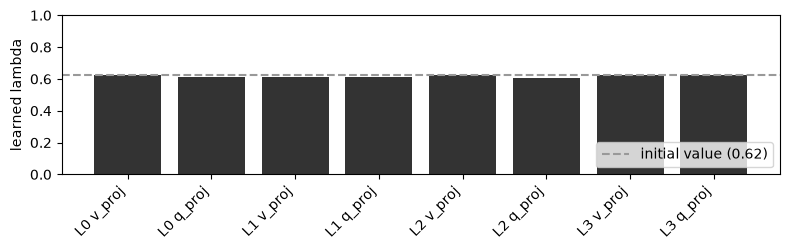

In [9]:
import matplotlib.pyplot as plt

lams = {name: m.lam.item() for name, m in rlora_clf.named_modules() if isinstance(m, RLoRALinear)}
for name, lam in lams.items():
    print(f"{name:60s} lambda = {lam:.4f}")

labels = [n.replace("encoder.layers.", "L").replace(".self_attn.", " ") for n in lams]
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.bar(range(len(lams)), list(lams.values()), color="0.2")
ax.axhline(1 / (1 + math.exp(-0.5)), color="0.6", linestyle="--", label="initial value (0.62)")
ax.set_xticks(range(len(lams)), labels, rotation=45, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("learned lambda")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### 3.3 Merging: LoRA can, R-LoRA cannot

After training, a LoRA update can be folded into the frozen weight
($W = W_0 + \tfrac{\alpha}{r}BA$) and the adapter disappears at inference. `peft` does it with
`merge_and_unload()`, and the outputs do not change. For R-LoRA there is no matrix to add:
the update depends on $\lVert x\rVert$, which changes with every input. The cell below
tries the naive merge and shows that it changes the model's output.

In [10]:
import copy

with torch.no_grad():
    # LoRA: merge and compare logits
    before = lora_clf(input_features=X_val).logits
    merged = copy.deepcopy(lora_clf).merge_and_unload()
    after = merged(input_features=X_val).logits
    print(f"LoRA   max |logits before - after merge| = {(before - after).abs().max().item():.2e}")

    # R-LoRA: a naive merge W0 + (alpha/r) B A ignores T_lambda
    naive = copy.deepcopy(rlora_clf)
    for parent in list(naive.modules()):
        for name, child in list(parent.named_children()):
            if isinstance(child, RLoRALinear):
                child.base.weight += (child.lora_B.weight @ child.lora_A.weight) * child.scaling
                setattr(parent, name, child.base)
    before = rlora_clf(input_features=X_val).logits
    after = naive(input_features=X_val).logits
    print(f"R-LoRA max |logits before - after naive merge| = {(before - after).abs().max().item():.2e}")

LoRA   max |logits before - after merge| = 4.77e-07


R-LoRA max |logits before - after naive merge| = 1.09e+00


### 3.4 Saving and reloading only the adapter

Without `peft`, the adapter is simply the trainable part of the state dict: the `lora_A`,
`lora_B` and `lambda_raw` tensors plus the new head. To reload it, inject R-LoRA into a clean
base model and load that dictionary. For deployment, the R-LoRA ASR system in ALBAYZIN 2026
went one step further: the adapted model was saved as a single self-contained Hugging Face
model with its own modelling code, so inference is one `from_pretrained` call.

In [11]:
import tempfile
from pathlib import Path

trainable_names = {n for n, p in rlora_clf.named_parameters() if p.requires_grad}
adapter_state = {k: v for k, v in rlora_clf.state_dict().items() if k in trainable_names}

with tempfile.TemporaryDirectory() as tmp_dir:
    path = Path(tmp_dir) / "whisper_tiny_classifier_rlora.pt"
    torch.save(adapter_state, path)
    print(f"Saved adapter: {path.stat().st_size / 1e6:.2f} MB ({len(adapter_state)} tensors)")

    reloaded = WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2)
    inject_rlora(reloaded, TARGETS, r=R, alpha=ALPHA, modules_to_save=HEADS)
    missing, unexpected = reloaded.load_state_dict(torch.load(path), strict=False)
    print("unexpected keys:", unexpected, "| missing keys that are trainable:", [k for k in missing if k in trainable_names])
    print(f"val accuracy after reloading: {accuracy(reloaded, X_val, y_val):.3f}")

Saved adapter: 0.60 MB (28 tensors)


unexpected keys: [] | missing keys that are trainable: []


val accuracy after reloading: 1.000


## 4. Part B -- Whisper as an embedding extractor with R-LoRA

The recipe of Part B of the LoRA tutorial, with R-LoRA: adapters on `q_proj`, `v_proj`,
`fc1` and `fc2` of the encoder (the embedding itself has to move, so the feed-forward layers
are adapted too), a throwaway linear *probe* to train them, and an external
`LogisticRegression` on mean-pooled embeddings before and after.

In [12]:
from sklearn.linear_model import LogisticRegression
from transformers import WhisperModel

whisper_full = WhisperModel.from_pretrained(CHECKPOINT)
encoder = whisper_full.get_encoder()
torch.manual_seed(0)
inject_rlora(encoder, ("q_proj", "v_proj", "fc1", "fc2"), r=4, alpha=8)
trainable, total = count_trainable(encoder)
print(f"trainable {trainable:,} of {total:,} ({100 * trainable / total:.2f}%)")


def embed(model, X):
    model.eval()
    with torch.no_grad():
        return model(input_features=X).last_hidden_state.mean(dim=1).numpy()


acc_before = LogisticRegression(max_iter=1000).fit(embed(encoder, X_train), y_train).score(embed(encoder, X_val), y_val)

scratch_probe = nn.Linear(whisper_full.config.d_model, 2)  # throwaway head
opt = torch.optim.AdamW([
    {"params": [p for p in encoder.parameters() if p.requires_grad], "lr": 1e-3 * scale},  # matched lr, as in 3.1
    {"params": scratch_probe.parameters(), "lr": 1e-3},
])
t0 = time.time()
for epoch in range(3):
    encoder.train()
    perm = torch.randperm(X_train.shape[0])
    for i in range(0, X_train.shape[0], 4):
        idx = perm[i : i + 4]
        opt.zero_grad()
        pooled = encoder(input_features=X_train[idx]).last_hidden_state.mean(dim=1)
        loss = nn.functional.cross_entropy(scratch_probe(pooled), y_train[idx])
        loss.backward()
        opt.step()
    print(f"epoch {epoch} | loss {loss.item():.4f} | {time.time() - t0:.1f}s")

acc_after = LogisticRegression(max_iter=1000).fit(embed(encoder, X_train), y_train).score(embed(encoder, X_val), y_val)
print(f"\nval accuracy, external LogisticRegression -- unadapted: {acc_before:.3f} | R-LoRA-adapted: {acc_after:.3f}")

trainable 86,032 of 8,294,416 (1.04%)


epoch 0 | loss 0.7746 | 10.3s


epoch 1 | loss 0.1592 | 19.6s


epoch 2 | loss 0.0016 | 29.0s



val accuracy, external LogisticRegression -- unadapted: 1.000 | R-LoRA-adapted: 1.000


## 5. Summary

| | LoRA (`peft`) | R-LoRA (this notebook) |
|---|---|---|
| Update | $\tfrac{\alpha}{r}BAx$ | $\tfrac{\alpha}{r}BA\,T_\lambda(x)$ |
| Extra parameters | -- | one λ per adapted layer |
| Initialisation | $B = 0$ | $B = 0$, $\lambda_0 \approx 0.62$ |
| Merge into $W_0$ after training | yes | no: the branch runs at inference |
| Where it pays off (paper) | -- | scarce data, crowded representations: +12.4 Macro-F1 over LoRA on four clinical corpora |

**Key takeaways:**
- R-LoRA is a ten-line change to LoRA: normalise the adapter's input by its norm to a
  learnable power. Everything else -- where to place adapters, rank, `modules_to_save`,
  the probe trick for embeddings -- is the same as in the LoRA tutorial.
- Check the three properties when you implement it: identity at initialisation, LoRA at
  λ = 0, non-linearity otherwise.
- Do not reuse LoRA's learning rate blindly: the branch sees an input scaled down by
  $\lVert x\rVert^{\lambda}$, so give the adapters a rate that matches, or tune it per method.
- Because it wraps `nn.Linear`, it applies to any Transformer. On Whisper-large-v3 for
  dialectal speech recognition it reached 26.31 % normalised WER against 29.24 % for LoRA
  on the ALBAYZIN 2026 blind test.
- Plan for the trade-off: no merging, so serve the adapted model as a whole.

**References:**
- R-LoRA: Ramírez-Sánchez, Docío-Fernández, García-Caballero and García-Mateo, *Radial LoRA: Enhancing Parameter-Efficient Fine-Tuning for Clinical Speech Assessment*, IberSPEECH 2026 -- https://jmramirez.engineer/research/radial-lora-clinical-2026/
- Walkthrough: https://jmramirez.engineer/writing/radial-lora/
- LoRA: Hu et al., 2021 -- [arXiv:2106.09685](https://arxiv.org/abs/2106.09685)
- Whisper: Radford et al., 2022 -- [arXiv:2212.04356](https://arxiv.org/abs/2212.04356)
- The LoRA version of this notebook: [whisper-peft-lora.ipynb](https://github.com/JMasr/ai-tutorials/blob/main/en/whisper-peft-lora.ipynb)